In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
import feature_engineering as fe
import predict

model = predict.load_model()

c:\Users\praja\anaconda3\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator FunctionTransformer from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\praja\anaconda3\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\praja\anaconda3\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.9.1 when using version 1.9.0. This might lead to brea

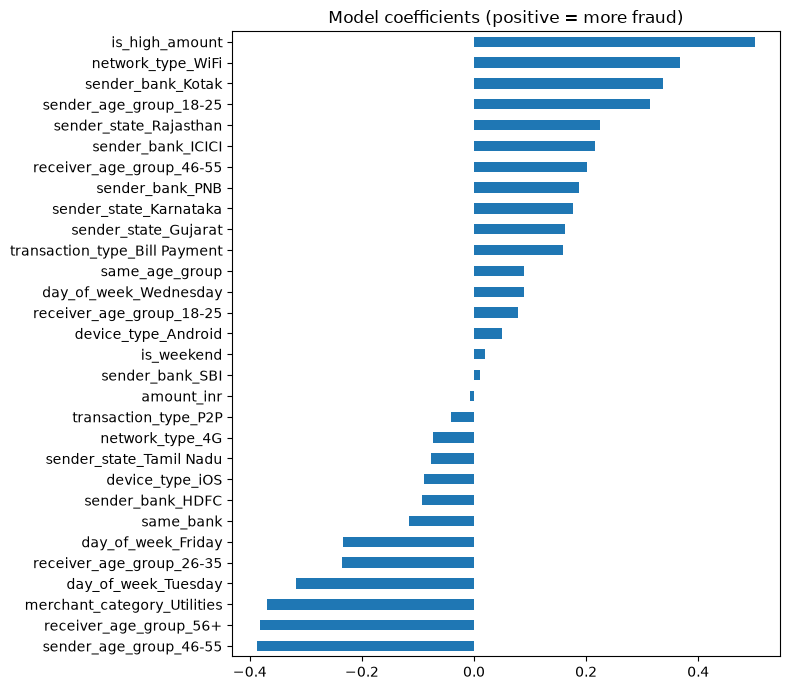

In [2]:
# 1. Coefficients of the Logistic Regression
encoder = model.named_steps["encode"]
selector = model.named_steps["select"]
names = [n.split("__", 1)[1] for n in encoder.get_feature_names_out()]
kept = [n for n, k in zip(names, selector.get_support()) if k]

coef = pd.Series(model.named_steps["model"].coef_[0], index=kept).sort_values()

plt.figure(figsize=(8, 7))
coef.plot(kind="barh")
plt.title("Model coefficients (positive = more fraud)")
plt.tight_layout()
plt.show()

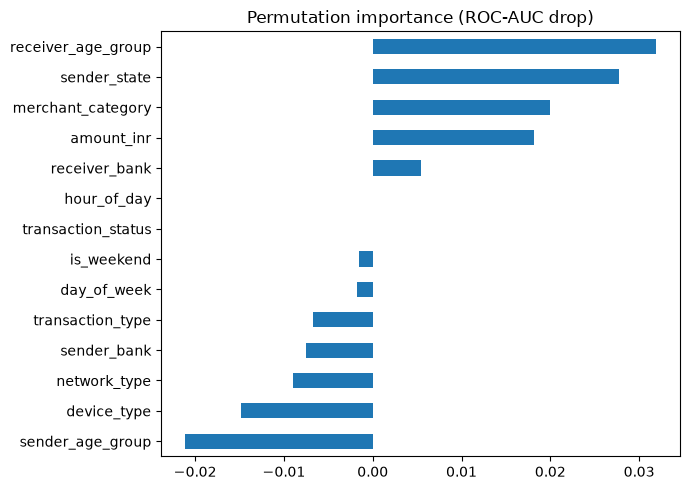

receiver_age_group    0.0319
sender_state          0.0278
merchant_category     0.0199
amount_inr            0.0182
receiver_bank         0.0055
transaction_status    0.0000
hour_of_day           0.0000
is_weekend           -0.0016
day_of_week          -0.0018
transaction_type     -0.0067
sender_bank          -0.0075
network_type         -0.0089
device_type          -0.0148
sender_age_group     -0.0212
dtype: float64

In [3]:
# 2. Permutation importance: how much does the score drop if we shuffle a column?
X_train, X_test, y_train, y_test = fe.load_train_test()
sample_X = X_test.sample(20000, random_state=42)
sample_y = y_test.loc[sample_X.index]

result = permutation_importance(model, sample_X, sample_y, scoring="roc_auc",
                                n_repeats=3, random_state=42, n_jobs=1)
importance = pd.Series(result.importances_mean, index=sample_X.columns)
importance = importance.sort_values()

plt.figure(figsize=(7, 5))
importance.plot(kind="barh")
plt.title("Permutation importance (ROC-AUC drop)")
plt.tight_layout()
plt.show()
importance.sort_values(ascending=False).round(4)

## Conclusions
- The model is Logistic Regression, so we can read the coefficients. The largest ones are
  small and point in many directions. `is_high_amount` is the strongest "more fraud" feature,
  which matches the EDA (0.275% vs 0.184%).
- Permutation importance values are all very small (below 0.04), and several are **negative**.
  Shuffling those columns made the score a bit better, which means they carry no useful signal.
- No single feature explains fraud. This matches the weak ROC-AUC.